# Final Project - Arielle Weinstein

## Part 1

In [1]:
#import packages
import pandas as pd
import psycopg2
import os

In [2]:
user = os.getenv('USER') #get user variable from environment
password = os.getenv('PASSWORD') #get password variable from environment
dbname = 'everything2024' #get the db name
host = 'pg.mlds.northwestern.edu' #host name
port = '5432' #port number

In [3]:
#connect to the server
connection = psycopg2.connect(
    dbname=dbname,
    user=user,
    password=password,
    host=host,
    port=port
)

In [4]:
cursor = connection.cursor() #create a cursor object through the connection

In [5]:
#view the tables 
cursor.execute("""
    SELECT table_name 
    FROM information_schema.tables
    WHERE table_schema = 'mlds422'
    ORDER BY table_name;
""")

tables = cursor.fetchall() #get all of the tables
print(tables) #print the tables
len(tables) #print the amount of tables

[('movies',)]


1

In [6]:
cursor.execute("SELECT * FROM mlds422.movies;") #select everything from the movies table
result = cursor.fetchall() #save to result variable

In [7]:
pd.DataFrame(result) #make a dataframe with the result

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,1,Percy Jackson & the Olympians: The Lightning T...,A teenager discovers he's the descendant of a ...,PG,"Action & Adventure, Comedy, Drama, Science Fic...",Chris Columbus,2010-02-12,2010-06-29,83.0,49,144,53.0,254287.0
1,2,Please Give,Kate has a lot on her mind. There's the ethics...,R,Comedy,Nicole Holofcener,2010-04-30,2010-10-19,90.0,86,140,64.0,11567.0
2,3,10,Blake Edwards' 10 stars Dudley Moore as George...,R,"Comedy, Romance",Blake Edwards,1979-10-05,1997-08-27,118.0,68,22,53.0,14670.0
3,4,12 Angry Men (Twelve Angry Men),"A Puerto Rican youth is on trial for murder, a...",None,"Classics, Drama",Sidney Lumet,2057-04-13,2001-03-06,95.0,100,51,97.0,105000.0
4,5,"20,000 Leagues Under The Sea","This 1954 Disney version of Jules Verne's 20,0...",G,"Action & Adventure, Drama, Kids & Family",Richard Fleischer,2054-01-01,2003-05-20,127.0,89,27,74.0,68860.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
16633,16633,Zoom,Former superhero Jack is called back to work t...,PG,"Action & Adventure, Comedy, Kids & Family",Peter Hewitt,2006-08-11,2007-09-02,88.0,3,66,33.0,11327.0
16634,16635,Zootopia,The modern mammal metropolis of Zootopia is a ...,PG,"Action & Adventure, Animation, Comedy","Byron Howard, Rich Moore, Jared Bush",2016-03-04,2016-06-07,108.0,97,279,92.0,100946.0
16635,16636,Zorba the Greek,If ever there was a role that Anthony Quinn wa...,None,"Action & Adventure, Art House & International,...",None,2064-12-17,2004-08-03,142.0,78,9,87.0,7126.0
16636,16637,Zulu,"Filmed on a grand scale, Zulu is a rousing rec...",PG,"Classics, Drama","Cy Endfield, Cyril Endfield",2064-06-17,2001-02-02,139.0,95,21,91.0,30170.0


In [8]:
column_names = [desc[0] for desc in cursor.description] #get the column names from the description
data = pd.DataFrame(result, columns=column_names) #set the column names to the dataframe and save as "data"

In [9]:
cursor.close() #close the cursor and connection
connection.close()

## Part 2

### 1.

In [10]:
data.to_csv('422final_data.csv') #write the data to a csv file

In [11]:
data.head() #view the first few rows

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count
0,1,Percy Jackson & the Olympians: The Lightning T...,A teenager discovers he's the descendant of a ...,PG,"Action & Adventure, Comedy, Drama, Science Fic...",Chris Columbus,2010-02-12,2010-06-29,83.0,49,144,53.0,254287.0
1,2,Please Give,Kate has a lot on her mind. There's the ethics...,R,Comedy,Nicole Holofcener,2010-04-30,2010-10-19,90.0,86,140,64.0,11567.0
2,3,10,Blake Edwards' 10 stars Dudley Moore as George...,R,"Comedy, Romance",Blake Edwards,1979-10-05,1997-08-27,118.0,68,22,53.0,14670.0
3,4,12 Angry Men (Twelve Angry Men),"A Puerto Rican youth is on trial for murder, a...",None,"Classics, Drama",Sidney Lumet,2057-04-13,2001-03-06,95.0,100,51,97.0,105000.0
4,5,"20,000 Leagues Under The Sea","This 1954 Disney version of Jules Verne's 20,0...",G,"Action & Adventure, Drama, Kids & Family",Richard Fleischer,2054-01-01,2003-05-20,127.0,89,27,74.0,68860.0


In [12]:
data.info() #use the info function to view the data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16638 entries, 0 to 16637
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   movie_id            16638 non-null  int64  
 1   movie_title         16638 non-null  object 
 2   movie_info          16614 non-null  object 
 3   rating              11776 non-null  object 
 4   genre               16621 non-null  object 
 5   directors           16524 non-null  object 
 6   in_theaters_date    15823 non-null  object 
 7   on_streaming_date   16636 non-null  object 
 8   runtime_in_minutes  16483 non-null  float64
 9   critic_rating       16638 non-null  int64  
 10  critic_count        16638 non-null  int64  
 11  audience_rating     16381 non-null  float64
 12  audience_count      16386 non-null  float64
dtypes: float64(3), int64(3), object(7)
memory usage: 1.7+ MB


In [13]:
data.dtypes #look at data types

movie_id                int64
movie_title            object
movie_info             object
rating                 object
genre                  object
directors              object
in_theaters_date       object
on_streaming_date      object
runtime_in_minutes    float64
critic_rating           int64
critic_count            int64
audience_rating       float64
audience_count        float64
dtype: object

In [14]:
#change in_theaters_date and on_streaming_date to datetime format
data['in_theaters_date'] = pd.to_datetime(data['in_theaters_date']) 
data['on_streaming_date'] = pd.to_datetime(data['on_streaming_date'])

In [15]:
data['release_year'] = data['in_theaters_date'].dt.year #create new column with release year by extracting from in_theaters_date

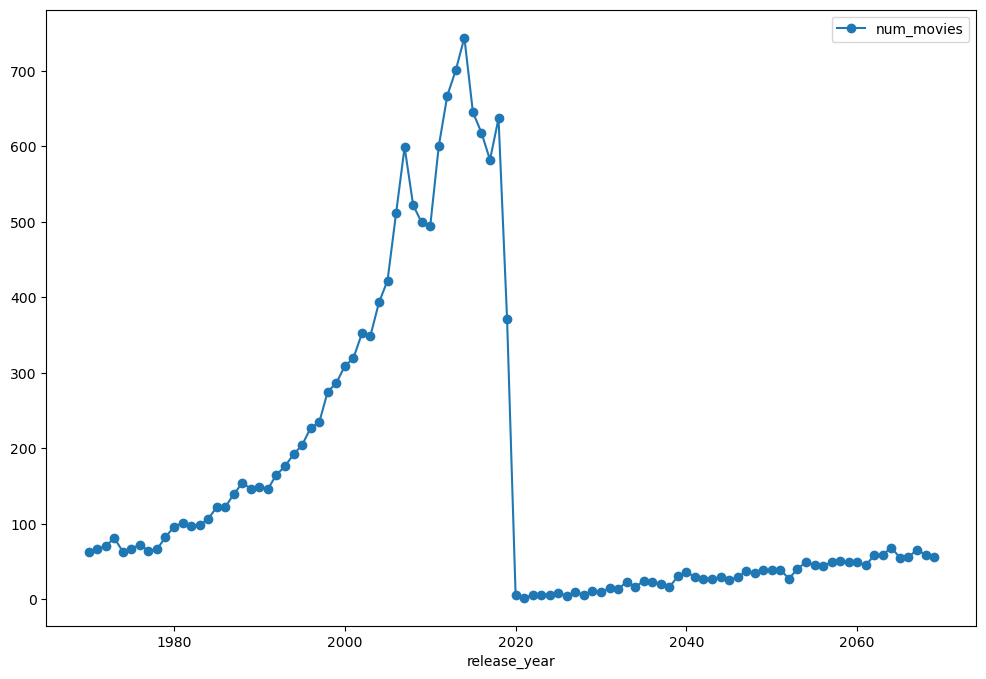

In [16]:
import matplotlib.pyplot as plt #import plotting
year_plot = (
    data.groupby('release_year') #group by year
    .agg({'movie_id':'count'}) #cound the number of movies per year
    .rename(columns={'movie_id':'num_movies'}) #rename columns
    .plot(kind='line', marker = 'o', figsize=(12,8)) #plot with o as the marker
            )

There seems to be a steep drop off at the year 2019 where it looks like the data from after that year got shifted ahead by 100 years. I verified this by looking at the data after 2019 and seeing that those movies were from 1920 and onwards. Also this is especially apparent because the years 2026 and upwards have not occurred yet. I will shift all of the release dates back by 100 years if the year is greater than 2019. 

In [17]:
mask = data['in_theaters_date'].dt.year > 2019 #create a mask for years larger than 2019

data.loc[mask, 'in_theaters_date'] = (
    data.loc[mask, 'in_theaters_date'] - pd.DateOffset(years=100) #offset the years larger than 2019 by subtracting 100
)

In [18]:
data['release_year'] = data['in_theaters_date'].dt.year #reset the release_year column with the updated in_theaters_date data

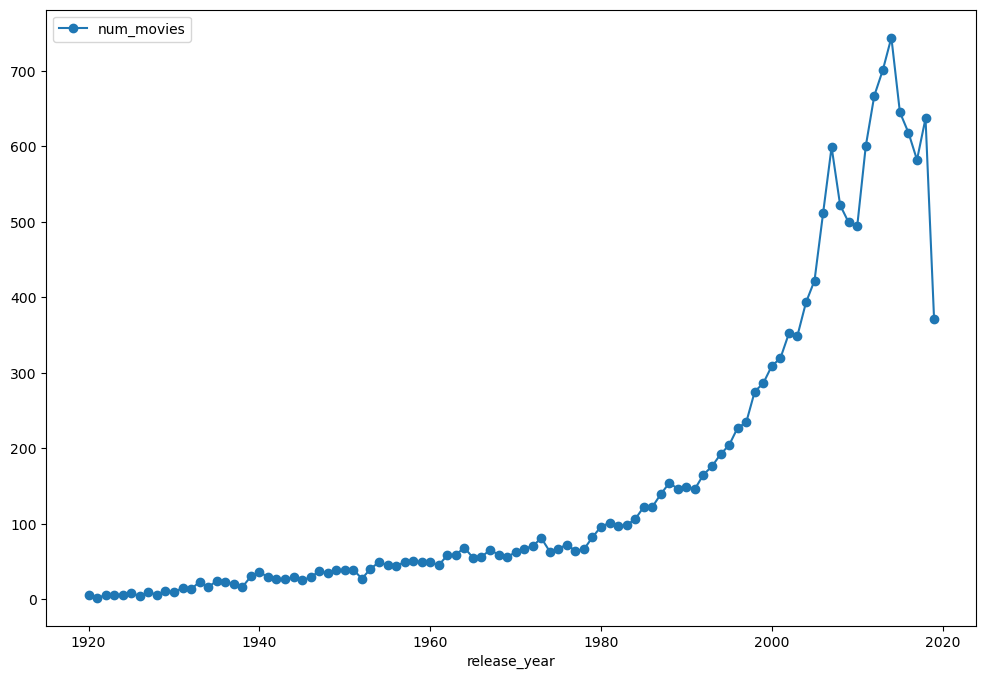

In [19]:
#replot the year plot with the updated data
year_plot = (
    data.groupby('release_year')
    .agg({'movie_id':'count'})
    .rename(columns={'movie_id':'num_movies'})
    .plot(kind='line', marker = 'o', figsize=(12,8))
            )

### 2.

Critic Rating

In [20]:
before_2010 = data[data['in_theaters_date'].dt.year < 2010] #create new df for movies release before 2010

In [21]:
before_2010.sort_values(by='critic_rating', ascending=False).head(5) #view the top 5 critic rated from this new df

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count,release_year
14217,14199,The Great Silence (Il grande silenzio),Italian filmmaker Sergio Corbucci directed thi...,None,"Art House & International, Drama, Western",Sergio Corbucci,1968-01-01,2004-01-27,105.0,100,11,90.0,6750.0,1968.0
3063,3022,The Band Wagon,"A lavish, enduring backstage musical from Vinc...",None,"Classics, Comedy, Drama, Musical & Performing ...",Vincente Minnelli,1953-08-07,2005-03-15,112.0,100,18,82.0,4679.0,1953.0
534,515,The Invisible Man,"A mysterious stranger, his face swathed in ban...",None,"Classics, Comedy, Horror, Science Fiction & Fa...",James Whale,1933-11-13,2001-08-28,72.0,100,37,85.0,11089.0,1933.0
10164,10121,Multiple Maniacs,"John Waters' gloriously grotesque, unavailable...",NC17,"Comedy, Horror",John Waters,1970-04-10,2017-03-21,90.0,100,20,73.0,1329.0,1970.0
6031,5995,Father (Father: Diary of One Week),"In The Father (Apa), Hungarian filmmaker Istva...",PG-13,"Art House & International, Drama",Istv√°n Szab√≥,1967-10-04,2004-08-03,89.0,100,5,77.0,372.0,1967.0


Audience Rating

In [22]:
before_2010.sort_values(by='audience_rating', ascending=False).head(5) #view the top 5 audience rated movies from the new df

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count,release_year
1846,1801,Ice People,While the mainstream world rolls on indefinite...,None,"Documentary, Special Interest",Anne Aghion,2008-04-26,2009-11-10,77.0,89,9,100.0,37.0,2008.0
222,216,Prima Ballerina,In the grand tradition of the Ballet Russes co...,None,"Art House & International, Special Interest",Laurent Gentot,2009-01-16,2009-12-08,NaN,81,26,100.0,24.0,2009.0
3229,3197,Been Rich All My Life,This documentary follows the most unlikely tro...,None,"Documentary, Musical & Performing Arts, Specia...",Heather MacDonald,2006-07-21,2006-11-21,81.0,80,30,100.0,961.0,2006.0
1283,1289,La Ciudad (The City),This American film (in Spanish) focuses on Lat...,None,"Art House & International, Drama",David Riker,1998-09-13,2005-06-14,88.0,83,12,100.0,313.0,1998.0
6747,6704,The Godfather,Popularly viewed as one of the best American f...,R,Drama,Francis Ford Coppola,1972-03-24,2001-10-09,175.0,98,91,98.0,732931.0,1972.0


### 3.

In [23]:
mean_audience = before_2010['audience_count'].mean() #calculate mean of audience_count
mean_audience

np.float64(245028.4832560536)

In [24]:
popular_2010 = before_2010[before_2010['audience_count'] > mean_audience] #create new df defined by popular movies having audience counts greater than the mean
popular_2010

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count,release_year
5,6,"10,000 B.C.",A young outcast from a primitive tribe is forc...,PG-13,"Action & Adventure, Classics, Drama",Roland Emmerich,2008-03-07,2008-06-24,109.0,8,148,37.0,411087.0,2008.0
32,31,Ultraviolet,In the late 21st a disease called Hemophagia h...,PG-13,"Action & Adventure, Drama, Horror, Science Fic...",Kurt Wimmer,2006-03-03,2006-06-27,88.0,8,83,30.0,279966.0,2006.0
53,51,Aliens,"Big-budget special effects, swiftly paced acti...",R,"Action & Adventure, Horror, Science Fiction & ...",James Cameron,1986-07-18,1999-06-01,138.0,99,72,94.0,429158.0,1986.0
88,85,The Happening,"The Happening' is a lightning-paced, heart-pou...",R,"Drama, Mystery & Suspense, Science Fiction & F...",M. Night Shyamalan,2008-06-11,2008-10-07,90.0,18,179,24.0,370131.0,2008.0
95,144,The Box,Norma and Arthur Lewis are a suburban couple w...,PG-13,"Horror, Mystery & Suspense, Science Fiction & ...",Richard Kelly,2009-11-06,2010-02-23,116.0,44,155,24.0,359067.0,2009.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16595,16595,You've Got Mail,"The film tells of Kathleen Kelly, who owns a c...",PG,"Comedy, Drama, Romance",Nora Ephron,1998-12-18,1999-05-04,119.0,69,86,73.0,462318.0,1998.0
16606,16606,Zathura,Two young brothers are drawn into an intergala...,PG,"Action & Adventure, Kids & Family, Science Fic...",Jon Favreau,2005-11-11,2006-02-14,113.0,75,158,51.0,281155.0,2005.0
16623,16623,Zodiac,Based on the true story of the notorious seria...,R,Mystery & Suspense,David Fincher,2007-03-02,2007-07-24,157.0,89,248,77.0,493811.0,2007.0
16627,16627,Zombieland,A cowardly shut-in named Columbus (Jesse Eisen...,R,"Comedy, Horror",Ruben Fleischer,2009-10-02,2010-02-02,88.0,90,249,86.0,642759.0,2009.0


Critic Rating

In [25]:
popular_2010.sort_values(by='critic_rating', ascending=False).head(5) #look at the top 5 critic rated movies in popular df

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count,release_year
11227,11194,Pinocchio,When the gentle woodcarver Geppetto (Christian...,G,"Animation, Kids & Family, Musical & Performing...","Hamilton Luske, Ben Sharpsteen, Walt Disney, W...",1940-02-07,2009-03-10,88.0,100,51,73.0,279248.0,1940.0
15440,15416,Toy Story 2,"Toy Story 2' is the exciting, all-new sequel t...",G,"Animation, Comedy, Kids & Family",John Lasseter,1999-11-24,2000-10-17,92.0,100,169,86.0,999952.0,1999.0
13557,13528,The Terminator,A Cyborg has been sent from the future on a de...,R,"Action & Adventure, Science Fiction & Fantasy",James Cameron,1984-10-26,1997-09-03,108.0,100,61,89.0,775856.0,1984.0
9636,9588,Mary Poppins,Practically Perfect In Every Way' Mary Poppins...,G,"Classics, Comedy, Kids & Family, Musical & Per...",Robert Stevenson,1964-08-26,1998-03-24,139.0,100,50,86.0,682310.0,1964.0
15439,15415,Toy Story,"Woody, a traditional pull-string talking cowbo...",G,"Animation, Comedy, Kids & Family",John Lasseter,1995-11-22,2001-03-20,80.0,100,88,92.0,1109209.0,1995.0


Audience Rating

In [26]:
popular_2010.sort_values(by='audience_rating', ascending=False).head(5) #look at top 5 audience rated movies in popular df

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count,release_year
6747,6704,The Godfather,Popularly viewed as one of the best American f...,R,Drama,Francis Ford Coppola,1972-03-24,2001-10-09,175.0,98,91,98.0,732931.0,1972.0
12463,12436,The Shawshank Redemption,"In 1946, a banker named Andy Dufresne (Tim Rob...",R,Drama,Frank Darabont,1994-09-10,1998-01-27,142.0,90,71,98.0,885508.0,1994.0
851,835,GoodFellas,Martin Scorsese explores the life of organized...,R,Drama,Martin Scorsese,1990-09-19,1997-03-26,146.0,96,95,97.0,428871.0,1990.0
6748,6705,"The Godfather, Part II",Francis Ford Coppola's legendary continuation ...,R,"Drama, Mystery & Suspense",Francis Ford Coppola,1974-12-20,2005-05-24,200.0,97,74,97.0,410868.0,1974.0
5706,5676,Star Wars: Episode V - The Empire Strikes Back,The second entry in George Lucas' Star Wars tr...,PG,"Action & Adventure, Drama, Science Fiction & F...",Irvin Kershner,1980-06-20,2004-09-21,124.0,95,98,97.0,1055106.0,1980.0


### 4. 

In [27]:
popular_2010['rating'].value_counts(dropna=False) #use value_counts to see how many movies of each rating there are

rating
PG-13    415
R        323
PG       196
G         64
None       1
Name: count, dtype: int64

1 movie (13 Ghosts) does not have a rating - for this, the rating was set to PG-13 because it is a horror movie and with some domain research it was determined that this would be the best choice. I tried to compare horror movies from 1960 to see their ratings but there were no other movies that fit this criteria. 

In [28]:
popular_2010[popular_2010['movie_title']== '13 Ghosts'] #find 13 Ghosts in df
popular_2010.loc[popular_2010['movie_title'] == '13 Ghosts', 'rating'] = 'PG-13' #set the rating to PG-13

In [29]:
counts = popular_2010['rating'].value_counts(dropna=False) #set the value counts to a variable

In [30]:
ratings = counts.index.tolist() #make the ratings into a list
ratings

['PG-13', 'R', 'PG', 'G']

In [31]:
values = counts.values.tolist() #make the count values into a list
values

[416, 323, 196, 64]

In [32]:
total_movies = sum(values) #calculate the total movies in the df
total_movies

999

In [33]:
rating_pers = [(x/total_movies)*100 for x in values] #calculate percentage of movies in each rating
rating_pers

[41.64164164164164, 32.33233233233233, 19.61961961961962, 6.406406406406406]

In [34]:
rating_dict = dict(zip(ratings, rating_pers)) #make into a dictionary with strings and percentages
print(rating_dict)

{'PG-13': 41.64164164164164, 'R': 32.33233233233233, 'PG': 19.61961961961962, 'G': 6.406406406406406}


Visualization

In [35]:
avg_ratings = (
        popular_2010.groupby('rating') #group by rating
        .agg({'critic_rating':'mean','audience_rating':'mean'}) #find mean audience and critic rating for each rating group
        .rename(columns={'critic_rating':'avg_critic_rating','audience_rating':'avg_audience_rating'}) #rename columns
        .reset_index() #reset index
              )
avg_ratings

,rating,avg_critic_rating,avg_audience_rating
0,G,77.765625,74.781250
1,PG,59.316327,65.331633
2,PG-13,49.141827,62.538462
3,R,61.811146,71.182663


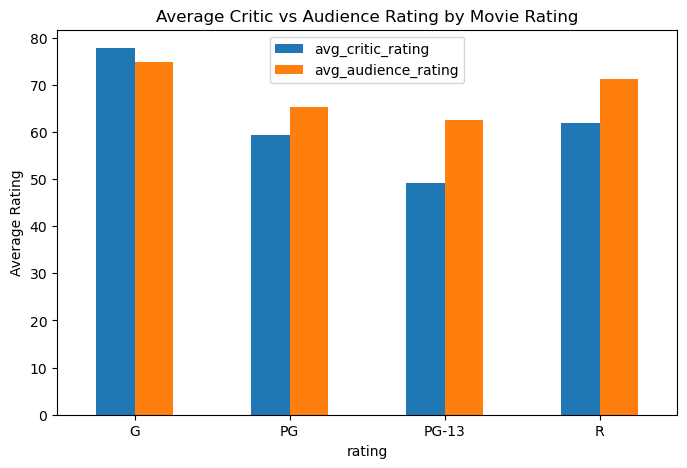

In [36]:
#make bar plot of the mean audience and critic ratings for each rating type
avg_ratings.plot(
    x='rating',
    y=['avg_critic_rating','avg_audience_rating'],
    kind='bar',
    figsize=(8,5)
)
plt.ylabel("Average Rating")
plt.title("Average Critic vs Audience Rating by Movie Rating")
plt.xticks(rotation=0)
plt.show()

Takeaways: The highest rated movies are those that are rated G as compared to the other 3 categories. PG-13 movies have the lowest average critic rating and average audience rating respectively. In the movies rated higher than G, critics tend to give lower ratings than the respective audience rating.

### 5. 

In [37]:
popular_2010.describe() #use describe to look at the data

,movie_id,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count,release_year
count,999.000000,999,999,999.000000,999.000000,999.000000,999.000000,9.990000e+02,999.000000
mean,7649.164164,2000-12-19 18:54:24.864864896,2004-08-05 14:49:22.162162176,109.229229,57.068068,134.392392,66.665666,2.152047e+06,2000.425425
min,6.000000,1937-12-21 00:00:00,1997-03-26 00:00:00,2.000000,0.000000,5.000000,16.000000,2.450460e+05,1937.000000
25%,3642.000000,1998-07-26 12:00:00,2001-08-07 00:00:00,94.000000,36.000000,78.000000,53.000000,3.387420e+05,1998.000000
50%,7325.000000,2004-03-19 00:00:00,2004-12-21 00:00:00,105.000000,58.000000,133.000000,69.000000,4.329160e+05,2004.000000
75%,11564.500000,2007-03-10 12:00:00,2007-09-04 00:00:00,120.000000,81.000000,182.000000,82.000000,6.924105e+05,2007.000000
max,16631.000000,2009-12-25 00:00:00,2014-02-11 00:00:00,222.000000,100.000000,348.000000,98.000000,3.579764e+07,2009.000000
std,4677.720378,NaN,NaN,21.390737,26.483696,65.720061,18.338728,7.066907e+06,10.155909


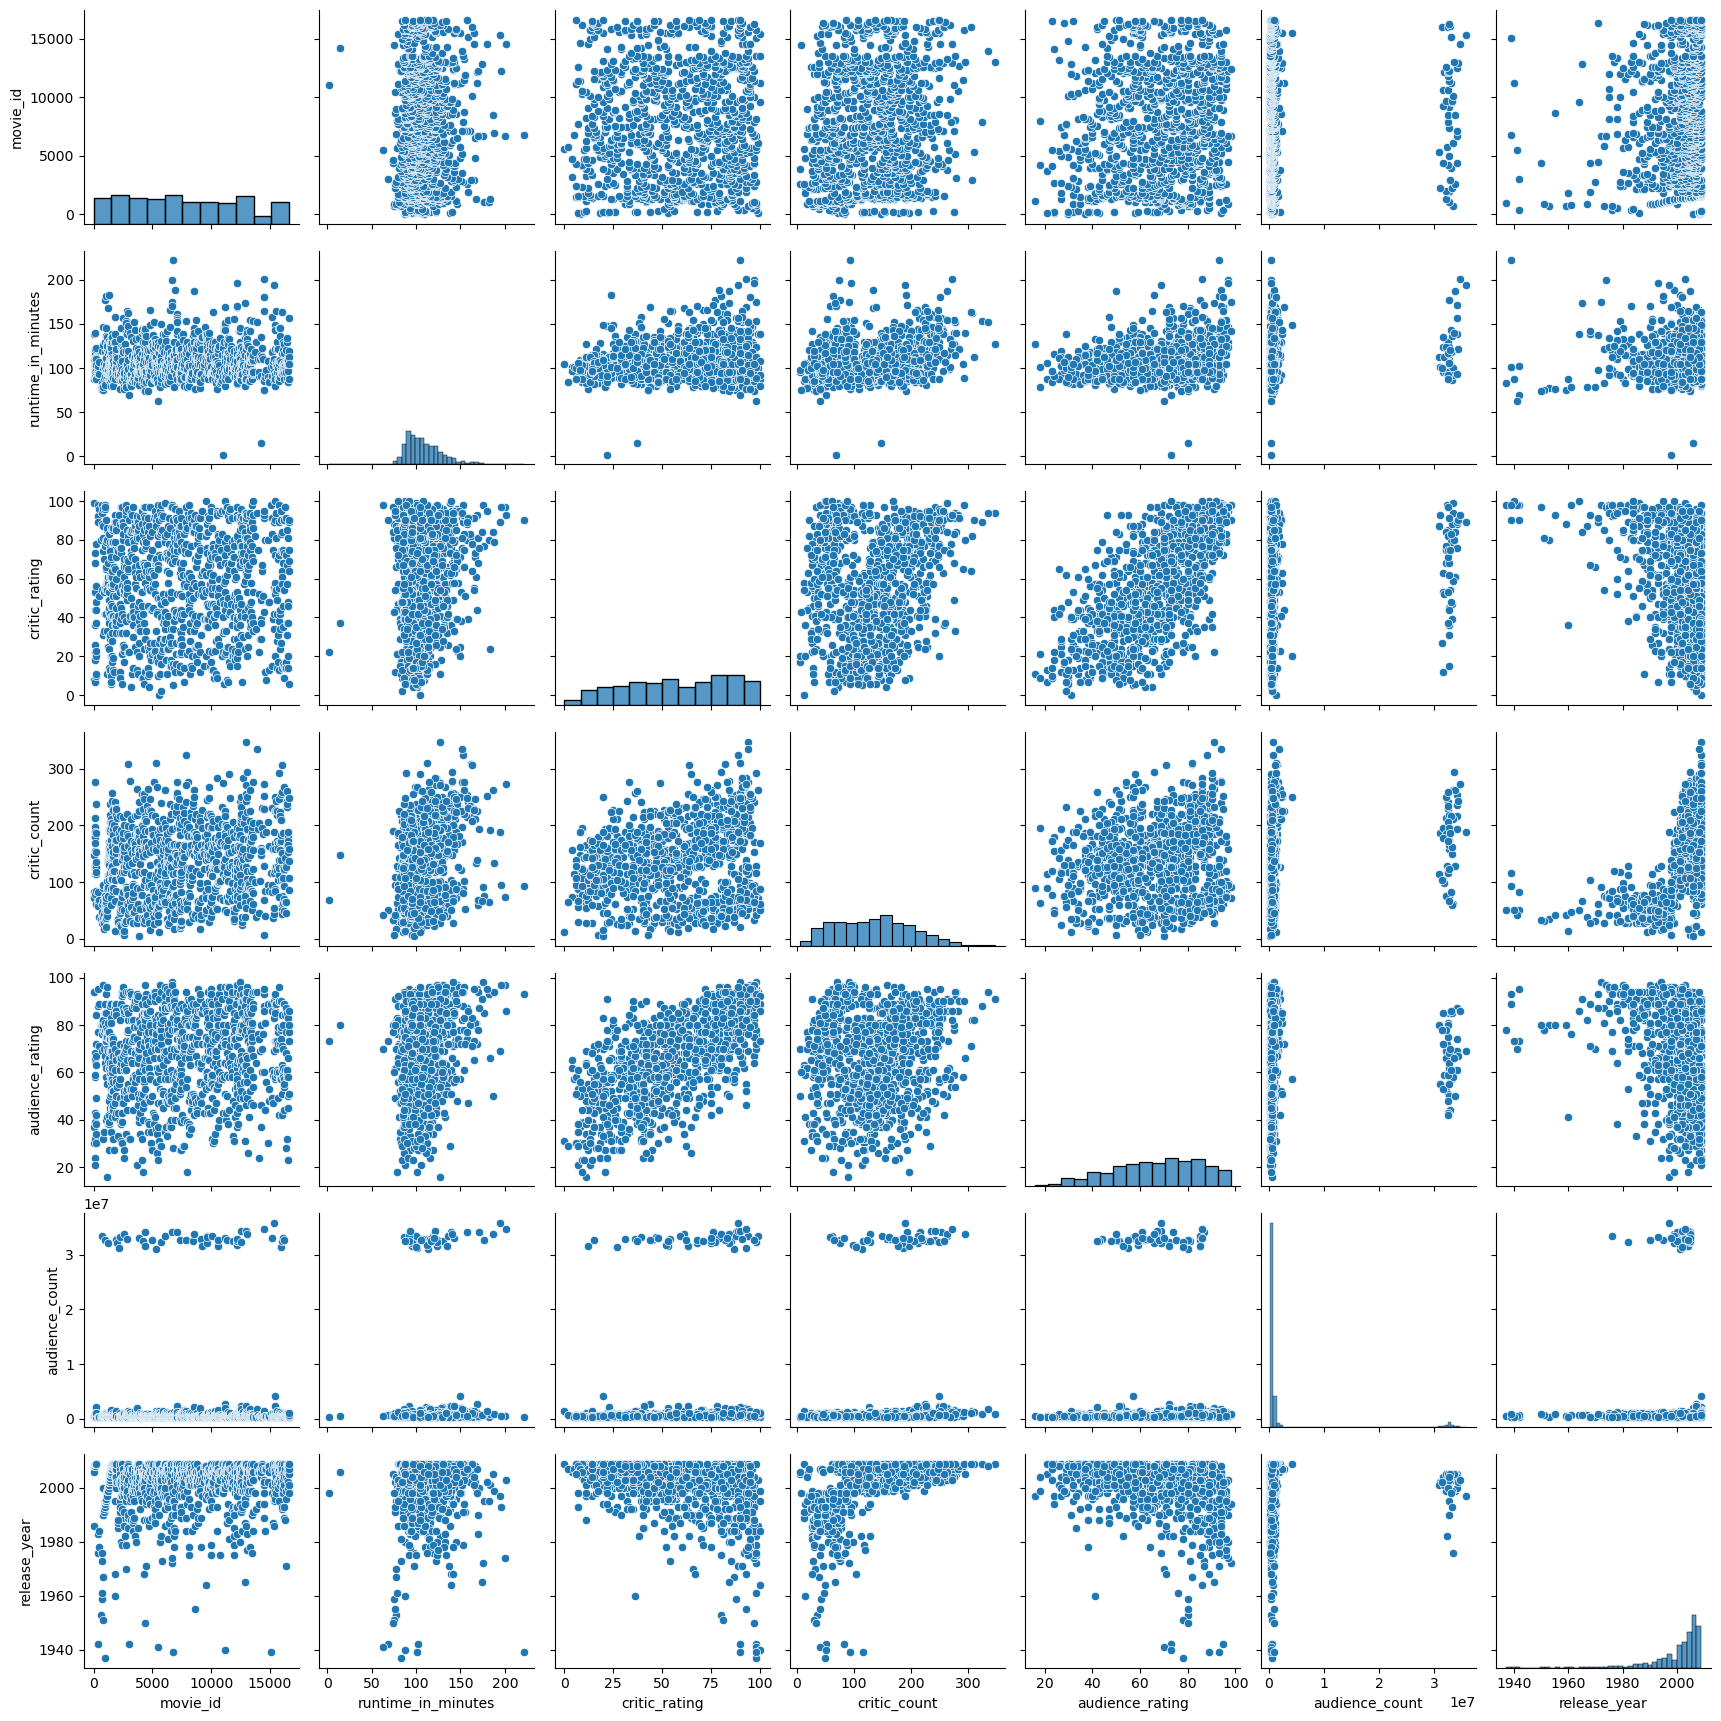

In [38]:
import seaborn as sns #import seaborn
sns.pairplot(popular_2010) #create pairplot

Insights:
1. The audience rating and critic rating relationship is largely linear, meaning that when an audience member rated a movie highly, it is likely that the critics also did.
2. Many more popular movies were released after 2000 as compared to before 2000.
3. There are a few select movies that have much higher numbers of audience reviews as compared to other movies. These movies tended to be released later as compared to others - more towards the year 2000.

### 6.

Top 5 popular movies before 2010 by critic rating and audience rating

In [39]:
top5_kids = (
    popular_2010[popular_2010['genre'].str.contains('Kids')] #select the movies with "Kids" in the genre string
        .sort_values(by=['critic_rating','audience_rating'], ascending=[False,False]) #sort by critic and audienc erating
        .head(5) #view top 5
)
top5_kids

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count,release_year
15439,15415,Toy Story,"Woody, a traditional pull-string talking cowbo...",G,"Animation, Comedy, Kids & Family",John Lasseter,1995-11-22,2001-03-20,80.0,100,88,92.0,1109209.0,1995.0
9636,9588,Mary Poppins,Practically Perfect In Every Way' Mary Poppins...,G,"Classics, Comedy, Kids & Family, Musical & Per...",Robert Stevenson,1964-08-26,1998-03-24,139.0,100,50,86.0,682310.0,1964.0
15440,15416,Toy Story 2,"Toy Story 2' is the exciting, all-new sequel t...",G,"Animation, Comedy, Kids & Family",John Lasseter,1999-11-24,2000-10-17,92.0,100,169,86.0,999952.0,1999.0
11227,11194,Pinocchio,When the gentle woodcarver Geppetto (Christian...,G,"Animation, Kids & Family, Musical & Performing...","Hamilton Luske, Ben Sharpsteen, Walt Disney, W...",1940-02-07,2009-03-10,88.0,100,51,73.0,279248.0,1940.0
6139,6104,Finding Nemo,"In this stunning underwater adventure, with me...",G,"Animation, Comedy, Kids & Family","Andrew Stanton, Lee Unkrich",2003-05-30,2013-05-07,100.0,99,263,86.0,33356856.0,2003.0


Highest difference between critic and audience rating of popular movies before 2010

In [40]:
popular_2010['rating_diff'] = popular_2010['critic_rating'] - popular_2010['audience_rating'] #calculate rating difference between critic and audience rating

/var/folders/yf/148hmqss1_vgnd31c0f91sxm0000gn/T/ipykernel_73304/786834606.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  popular_2010['rating_diff'] = popular_2010['critic_rating'] - popular_2010['audience_rating'] #calculate rating difference between critic and audience rating


In [41]:
highest_diff = (
    popular_2010.assign(rating_diff_abs = popular_2010['rating_diff'].abs()) #take the absolute value of the difference
    .sort_values(by='rating_diff', ascending=False) #sort from largest to smallest
    .head(5) #view top 5
)
highest_diff

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count,release_year,rating_diff,rating_diff_abs
12990,12966,Spy Kids,Gregorio and Ingrid are the two greatest secre...,PG,"Action & Adventure, Comedy, Kids & Family, Mys...",Robert Rodriguez,2001-03-30,2001-09-18,88.0,93,127,46.0,427343.0,2001.0,47.0,47.0
2766,2725,Antz,Central Park ant drone Z longs to be an indivi...,PG,"Animation, Comedy, Kids & Family, Science Fict...","Eric Darnell, Tim Johnson",1998-10-02,1999-03-23,83.0,93,92,52.0,651914.0,1998.0,41.0,41.0
13162,13133,Stop-Loss,"After serving his tour of duty in Iraq, a youn...",R,Drama,Kimberly Peirce,2008-03-13,2008-07-08,111.0,65,142,26.0,748288.0,2008.0,39.0,39.0
2240,2191,About a Boy,Will is a 36-year-old underachiever with a fea...,PG-13,"Comedy, Drama, Romance","Chris Weitz, Paul Weitz",2002-05-17,2003-01-14,101.0,93,187,55.0,31164074.0,2002.0,38.0,38.0
1697,1657,The Informant!,A rising star in the agricultural industry sud...,R,"Comedy, Drama, Mystery & Suspense",Steven Soderbergh,2009-09-18,2010-02-23,108.0,79,229,44.0,359235.0,2009.0,35.0,35.0


Average Runtime by Year

In [42]:
avg_runtime_year = (
    popular_2010.groupby('release_year') #group by release year
    .agg({'runtime_in_minutes':'mean'}) #take the average runtime of the movies per year
    .rename(columns={'runtime_in_minutes':'avg_runtime_min'}) #rename columns
    .reset_index() #reset index
)
avg_runtime_year

,release_year,avg_runtime_min
0,1937.0,83.000000
1,1939.0,161.500000
2,1940.0,88.000000
3,1941.0,63.000000
4,1942.0,85.500000
5,1950.0,74.000000
6,1951.0,75.000000
7,1953.0,77.000000
8,1955.0,76.000000
9,1959.0,75.000000


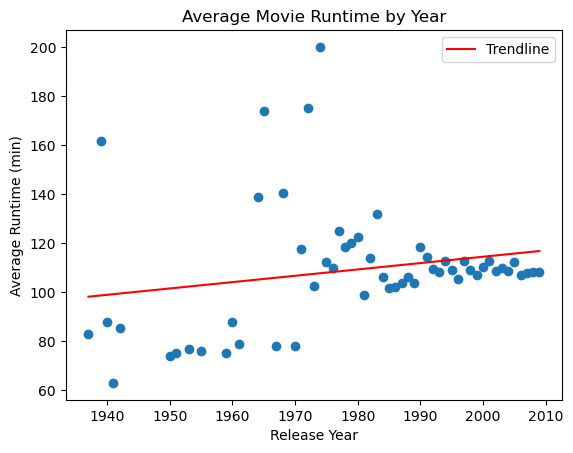

In [43]:
import numpy as np
plt.scatter(avg_runtime_year['release_year'],avg_runtime_year['avg_runtime_min']) #create scatter plot
coeffs = np.polyfit(avg_runtime_year['release_year'], avg_runtime_year['avg_runtime_min'], deg=1) #get coefficients for line of best fit
trendline = np.poly1d(coeffs) #create trendline 
#plot data and trendline
plt.plot(avg_runtime_year['release_year'], trendline(avg_runtime_year['release_year']), color='red', label='Trendline')

#plot specifications
plt.xlabel('Release Year')
plt.ylabel('Average Runtime (min)')
plt.title('Average Movie Runtime by Year')
plt.legend()
plt.show()

On the whole, popular movies before 2010 increased in average runtime as time progressed. This can be especially seen in the jump in average runtime from the 1950s and 1960s to the 2000s.

## Part 3

### 7.

In [44]:
data.head() #view the original data frame

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,critic_rating,critic_count,audience_rating,audience_count,release_year
0,1,Percy Jackson & the Olympians: The Lightning T...,A teenager discovers he's the descendant of a ...,PG,"Action & Adventure, Comedy, Drama, Science Fic...",Chris Columbus,2010-02-12,2010-06-29,83.0,49,144,53.0,254287.0,2010.0
1,2,Please Give,Kate has a lot on her mind. There's the ethics...,R,Comedy,Nicole Holofcener,2010-04-30,2010-10-19,90.0,86,140,64.0,11567.0,2010.0
2,3,10,Blake Edwards' 10 stars Dudley Moore as George...,R,"Comedy, Romance",Blake Edwards,1979-10-05,1997-08-27,118.0,68,22,53.0,14670.0,1979.0
3,4,12 Angry Men (Twelve Angry Men),"A Puerto Rican youth is on trial for murder, a...",None,"Classics, Drama",Sidney Lumet,1957-04-13,2001-03-06,95.0,100,51,97.0,105000.0,1957.0
4,5,"20,000 Leagues Under The Sea","This 1954 Disney version of Jules Verne's 20,0...",G,"Action & Adventure, Drama, Kids & Family",Richard Fleischer,1954-01-01,2003-05-20,127.0,89,27,74.0,68860.0,1954.0


In [45]:
train = data[data['release_year'] <2010].copy() #create train df based on movies before 2010
test = data[data['release_year'] > 2010].copy() #create test df base on movies after 2010

### 8.

In [46]:
X_train = train.drop(columns=['critic_rating','critic_count']) #drop critic rating and count from the training data
y_train = train['critic_rating'] #only use the critic rating in the y train

In [47]:
X_test = test.drop(columns=['critic_rating','critic_count']) #drop the critic rating and count from test data
y_test = test['critic_rating'] #use only the critic rating in the y test

We don't want to include the target variable as well as anything that the model should not know prior to the release date. This includes the audience reviews and the counts for both critic reviews and audience reviews because this information does not become available until after the release.

In [48]:
X_test.isna().sum() #see how many null values there are in the test data

movie_id                 0
movie_title              0
movie_info               1
rating                2176
genre                    5
directors               53
in_theaters_date         0
on_streaming_date        0
runtime_in_minutes     123
audience_rating         96
audience_count          94
release_year             0
dtype: int64

In [49]:
median_runtime = X_train['runtime_in_minutes'].median() #get the median runtime from the training data
X_test['runtime_in_minutes'] = X_test['runtime_in_minutes'].fillna(median_runtime) #fill in the null values in the test data with the median runtime from the training data

In [50]:
X_test.isna().sum() #see if the null values are gone

movie_id                 0
movie_title              0
movie_info               1
rating                2176
genre                    5
directors               53
in_theaters_date         0
on_streaming_date        0
runtime_in_minutes       0
audience_rating         96
audience_count          94
release_year             0
dtype: int64

### 9.

In [51]:
X_train = X_train.reset_index(drop=True) #reset the index to ensure when the model is fit nothing mismatches

In [52]:
model_df_train = X_train[['movie_id','movie_title','runtime_in_minutes']] #create df with id, title, and runtime

In [53]:
kid_friendly_array = np.where(
    X_train['rating'].isin(['G', 'PG']),  #if the rating exists and is PG or G set the value to 1
    1,
    np.where(
        X_train['rating'].isna() & #if the rating is missing
        X_train['genre'].str.contains('Kids', na=False), #and the genre contains "Kids"
        1, #also set the value to 1
        0  #otherwise set it to 0
    )
)
kid_friendly = pd.Series(kid_friendly_array, name='kid_friendly') #make the array into a series
kid_friendly.head(3)

movie_title_kid_f = pd.concat([model_df_train, kid_friendly],axis=1)[['movie_id','kid_friendly']] #make a df with model_df_train and kid_friendly
movie_title_kid_f.head(3)

,movie_id,kid_friendly
0,3,0
1,4,0
2,5,1


In [54]:
movie_title_kid_f.index.equals(X_train.index) #check that the indices are the same

True

In [55]:
#merge the two dataframes so that model_df_train has all of the columns
model_df_train = pd.merge(
    model_df_train,
    movie_title_kid_f,
    on='movie_id',
    how='left'
)
model_df_train.head() #view updated df

,movie_id,movie_title,runtime_in_minutes,kid_friendly
0,3,10,118.0,0
1,4,12 Angry Men (Twelve Angry Men),95.0,0
2,5,"20,000 Leagues Under The Sea",127.0,1
3,6,"10,000 B.C.",109.0,0
4,7,The 39 Steps,87.0,0


In [56]:
#make sure the lengths are the same
print(len(model_df_train))
print(len(X_train))

9764
9764


In [57]:
X_train['genre'].isna().sum() #see how many null values there are in genre

np.int64(1)

In [58]:
#helper function to clean genres
def clean_genre_list(val):
    '''Function to clean the genre list for each movie.'''
    if val is None or pd.isna(val): #if there isn't a genre
        return []  #nothing
    genres = [g.strip() for g in val.split(',') if g.strip() != ''] #split by commas, remove whitespace
    return sorted(set(genres))  #remove duplicates

In [59]:
clean_genres = X_train['genre'].apply(clean_genre_list).str.join(',') #clean the X_train genres

genres = clean_genres.str.get_dummies(sep=',').astype(int) #get rid of whitespace
genres['movie_id'] = X_train['movie_id'] #add a column for movie_id in genres so it can be merged with model_df_train

In [60]:
model_df_train = pd.merge(model_df_train, genres, on='movie_id', how='left') #merge with model_df_train
model_df_train.head() #view updated df

,movie_id,movie_title,runtime_in_minutes,kid_friendly,Action & Adventure,Animation,Anime & Manga,Art House & International,Classics,Comedy,...,Horror,Kids & Family,Musical & Performing Arts,Mystery & Suspense,Romance,Science Fiction & Fantasy,Special Interest,Sports & Fitness,Television,Western
0,3,10,118.0,0,0,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
1,4,12 Angry Men (Twelve Angry Men),95.0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,5,"20,000 Leagues Under The Sea",127.0,1,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
3,6,"10,000 B.C.",109.0,0,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
4,7,The 39 Steps,87.0,0,1,0,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0


In [61]:
model_df_train.index.equals(X_train.index) #make sure the indices are the same

True

### 10.

In [62]:
X_train.head() #view the X_train df to see what features to make

,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,audience_rating,audience_count,release_year
0,3,10,Blake Edwards' 10 stars Dudley Moore as George...,R,"Comedy, Romance",Blake Edwards,1979-10-05,1997-08-27,118.0,53.0,14670.0,1979.0
1,4,12 Angry Men (Twelve Angry Men),"A Puerto Rican youth is on trial for murder, a...",None,"Classics, Drama",Sidney Lumet,1957-04-13,2001-03-06,95.0,97.0,105000.0,1957.0
2,5,"20,000 Leagues Under The Sea","This 1954 Disney version of Jules Verne's 20,0...",G,"Action & Adventure, Drama, Kids & Family",Richard Fleischer,1954-01-01,2003-05-20,127.0,74.0,68860.0,1954.0
3,6,"10,000 B.C.",A young outcast from a primitive tribe is forc...,PG-13,"Action & Adventure, Classics, Drama",Roland Emmerich,2008-03-07,2008-06-24,109.0,37.0,411087.0,2008.0
4,7,The 39 Steps,A man in London tries to help a counterespiona...,None,"Action & Adventure, Classics, Mystery & Suspense",Alfred Hitchcock,1935-08-01,2035-06-06,87.0,86.0,23827.0,1935.0


In [63]:
#creating audience rating bin feature
#conditions for being in each bin
conds = [
    (X_train['audience_rating'] <= 20),
    (X_train['audience_rating'] <= 40),
    (X_train['audience_rating'] <= 60),
    (X_train['audience_rating'] <= 80),
    (X_train['audience_rating'] > 80)
]

choices = [1, 2, 3, 4, 5]

aud_rating_bin = np.select(conds, choices) #use np.select to assign values to each bin
aud_rating_bin = pd.Series(aud_rating_bin, name='audience_rating_bin', index=X_train.index) #create into a sereis

In [64]:
movie_ids_rating = pd.concat([X_train, aud_rating_bin], axis=1)[['movie_id','audience_rating_bin']] #make a df with id and the rating bins
model_df_train = pd.merge(model_df_train, movie_ids_rating, on='movie_id', how='left') #merge to the model_df_train df

In [65]:
#is_popular feature
mean_audience = X_train['audience_count'].mean() #get the mean audience count
mean_audience

np.float64(245028.4832560536)

In [66]:
is_popular_array = np.where(X_train['audience_count'] > mean_audience, 1, 0) #set new feature for popular or not if the audience count is above the mean
is_popular = pd.Series(is_popular_array, name='is_popular') #make into a series

In [67]:
movie_ids_is_popular = pd.concat([X_train, is_popular], axis=1)[['movie_id','is_popular']] #make new df with id and is_popular
model_df_train = pd.merge(model_df_train, movie_ids_is_popular, on='movie_id', how='left') #merge with model_df_train on id
model_df_train.head() #view updated df

,movie_id,movie_title,runtime_in_minutes,kid_friendly,Action & Adventure,Animation,Anime & Manga,Art House & International,Classics,Comedy,...,Musical & Performing Arts,Mystery & Suspense,Romance,Science Fiction & Fantasy,Special Interest,Sports & Fitness,Television,Western,audience_rating_bin,is_popular
0,3,10,118.0,0,0,0,0,0,0,1,...,0,0,1,0,0,0,0,0,3,0
1,4,12 Angry Men (Twelve Angry Men),95.0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,5,0
2,5,"20,000 Leagues Under The Sea",127.0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,4,0
3,6,"10,000 B.C.",109.0,0,1,0,0,0,1,0,...,0,0,0,0,0,0,0,0,2,1
4,7,The 39 Steps,87.0,0,1,0,0,0,1,0,...,0,1,0,0,0,0,0,0,5,0


In [68]:
#is sequel feature
X_train['is_sequel'] = X_train['movie_title'].str.contains(
    r'(?:\s(II|III|IV|V|VI|VII|VIII|IX|X|[2-9]))$', #if the title has numerals or numbers at the end of the string
    regex=True
).astype(int) #checks if the last character is a number or numeric

/var/folders/yf/148hmqss1_vgnd31c0f91sxm0000gn/T/ipykernel_73304/1984324634.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  X_train['is_sequel'] = X_train['movie_title'].str.contains(


In [69]:
model_df_train['is_sequel'] = X_train['is_sequel'] #set the column in model_df_train to be the same from X_train
model_df_train.head() #view updated df

,movie_id,movie_title,runtime_in_minutes,kid_friendly,Action & Adventure,Animation,Anime & Manga,Art House & International,Classics,Comedy,...,Mystery & Suspense,Romance,Science Fiction & Fantasy,Special Interest,Sports & Fitness,Television,Western,audience_rating_bin,is_popular,is_sequel
0,3,10,118.0,0,0,0,0,0,0,1,...,0,1,0,0,0,0,0,3,0,0
1,4,12 Angry Men (Twelve Angry Men),95.0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,5,0,0
2,5,"20,000 Leagues Under The Sea",127.0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,4,0,0
3,6,"10,000 B.C.",109.0,0,1,0,0,0,1,0,...,0,0,0,0,0,0,0,2,1,0
4,7,The 39 Steps,87.0,0,1,0,0,0,1,0,...,1,0,0,0,0,0,0,5,0,0


In [70]:
model_df_train.index.equals(X_train.index) #ensure that the indices are the same

True

## Part 4

### 11.

In [71]:
X_test = X_test.reset_index(drop=True) #reset the index of the test set

In [72]:
model_df_test = X_test[['movie_id','movie_title','runtime_in_minutes']] #create model_df_test with the columns from X_test

In [73]:
#kid_friendly feature
kid_friendly_array = np.where(
    X_test['rating'].isin(['G', 'PG']), #if the rating is PG or G set value to 1
    1,
    np.where(
        X_test['rating'].isna() &  #if the rating is missing
        X_test['genre'].str.contains('Kids', na=False), #and the genres contain "Kids" set value to 1
        1,
        0  #otherwise set value to 0
    )
)
kid_friendly = pd.Series(kid_friendly_array, name='kid_friendly') #make a series
kid_friendly.head(3)

movie_title_kid_f = pd.concat([model_df_test, kid_friendly],axis=1)[['movie_id','kid_friendly']] #create df with model_df_test and kid_friendly
movie_title_kid_f.head(3)

,movie_id,kid_friendly
0,98,0
1,156,0
2,217,0


In [74]:
#merge model_df_test and kid_friendly
model_df_test = pd.merge(
    model_df_test,
    movie_title_kid_f,
    on='movie_id',
    how='left'
)
model_df_test.head() #view the updated df

,movie_id,movie_title,runtime_in_minutes,kid_friendly
0,98,Fireflies in the Garden,98.0,0
1,156,Priest,83.0,0
2,217,Season of the Witch,92.0,0
3,190,"1,000 Times Good Night",117.0,0
4,248,Last Ride,100.0,0


In [75]:
#genres
clean_genres = X_test['genre'].apply(clean_genre_list).str.join(',') #use clean_genre_list function from earlier

genres = clean_genres.str.get_dummies(sep=',').astype(int) #get rid of whitespace from genres
genres['movie_id'] = X_test['movie_id'].values #set the id column in genres

In [76]:
model_df_test = pd.merge(model_df_test, genres, on='movie_id', how='left') #merge model_df_test and genres
model_df_test.head() #view the updated df

,movie_id,movie_title,runtime_in_minutes,kid_friendly,Action & Adventure,Animation,Anime & Manga,Art House & International,Classics,Comedy,...,Horror,Kids & Family,Musical & Performing Arts,Mystery & Suspense,Romance,Science Fiction & Fantasy,Special Interest,Sports & Fitness,Television,Western
0,98,Fireflies in the Garden,98.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,156,Priest,83.0,0,1,0,0,0,0,0,...,1,0,0,1,0,1,0,0,0,1
2,217,Season of the Witch,92.0,0,1,0,0,0,0,0,...,0,0,0,1,0,1,0,0,0,0
3,190,"1,000 Times Good Night",117.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,248,Last Ride,100.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [77]:
model_df_test.index.equals(X_test.index) #make sure that the indices match


True

In [78]:
#audience rating bins
conds = [
    (X_test['audience_rating'] <= 20),
    (X_test['audience_rating'] <= 40),
    (X_test['audience_rating'] <= 60),
    (X_test['audience_rating'] <= 80),
    (X_test['audience_rating'] > 80)
]

choices = [1, 2, 3, 4, 5]

aud_rating_bin = np.select(conds, choices) #assign values to each bin 
aud_rating_bin = pd.Series(aud_rating_bin, name='audience_rating_bin', index=X_test.index) #make a series with the bins and values

In [79]:
movie_ids_rating = pd.concat([X_test, aud_rating_bin], axis=1)[['movie_id','audience_rating_bin']] #create new df with id and bins
model_df_test = pd.merge(model_df_test, movie_ids_rating, on='movie_id', how='left') #merge model_df_test with the bins

In [80]:
#is_popular feature
mean_audience = X_test['audience_count'].mean() #calculate the mean of audience count in X_test
mean_audience

np.float64(16813.31657832206)

In [81]:
is_popular_array = np.where(X_test['audience_count'] > mean_audience, 1, 0) #if the audience count is above average assign 1 otherwise 0
is_popular = pd.Series(is_popular_array, name='is_popular') #make into a series

In [82]:
movie_ids_is_popular = pd.concat([X_test, is_popular], axis=1)[['movie_id','is_popular']]
model_df_test = pd.merge(model_df_test, movie_ids_is_popular, on='movie_id', how='left') #merge with model_df_test
model_df_test.head() #view the updated df


,movie_id,movie_title,runtime_in_minutes,kid_friendly,Action & Adventure,Animation,Anime & Manga,Art House & International,Classics,Comedy,...,Musical & Performing Arts,Mystery & Suspense,Romance,Science Fiction & Fantasy,Special Interest,Sports & Fitness,Television,Western,audience_rating_bin,is_popular
0,98,Fireflies in the Garden,98.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,3,1
1,156,Priest,83.0,0,1,0,0,0,0,0,...,0,1,0,1,0,0,0,1,3,1
2,217,Season of the Witch,92.0,0,1,0,0,0,0,0,...,0,1,0,1,0,0,0,0,2,1
3,190,"1,000 Times Good Night",117.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,4,0
4,248,Last Ride,100.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,4,0


In [83]:
#is_sequel feature
X_test['is_sequel'] = X_test['movie_title'].str.contains(
    r'(?:\s(II|III|IV|V|VI|VII|VIII|IX|X|[2-9]))$',
    regex=True
).astype(int) #checks if the last character is a number or numeric
X_test.head() #look at the updated df

/var/folders/yf/148hmqss1_vgnd31c0f91sxm0000gn/T/ipykernel_73304/2932818892.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  X_test['is_sequel'] = X_test['movie_title'].str.contains(


,movie_id,movie_title,movie_info,rating,genre,directors,in_theaters_date,on_streaming_date,runtime_in_minutes,audience_rating,audience_count,release_year,is_sequel
0,98,Fireflies in the Garden,"To an outsider, the Taylors are the very pictu...",R,Drama,Dennis Lee (III),2011-10-14,2012-02-07,98.0,45.0,45150.0,2011.0,0
1,156,Priest,"Priest, a western-fused post-apocalyptic thril...",PG-13,"Action & Adventure, Horror, Mystery & Suspense...",Scott Stewart,2011-05-13,2011-08-16,83.0,46.0,86566.0,2011.0,0
2,217,Season of the Witch,Oscar (R) winner Nicolas Cage (National Treasu...,PG-13,"Action & Adventure, Drama, Mystery & Suspense,...",Dominic Sena,2011-01-07,2011-06-28,92.0,30.0,79825.0,2011.0,0
3,190,"1,000 Times Good Night",Rebecca (Juliette Binoche) is one of world's t...,None,Drama,Erik Poppe,2014-10-24,2015-02-02,117.0,65.0,1881.0,2014.0,0
4,248,Last Ride,"In Last Ride, a desperate father takes his ten...",PG-13,Drama,Glendyn Ivin,2012-06-29,2012-10-16,100.0,65.0,3558.0,2012.0,0


In [84]:
model_df_test['is_sequel'] = X_train['is_sequel'] #set the is_sequel in model_df_test to be the same column from X_trainn
model_df_test.head() #view the updated df

,movie_id,movie_title,runtime_in_minutes,kid_friendly,Action & Adventure,Animation,Anime & Manga,Art House & International,Classics,Comedy,...,Mystery & Suspense,Romance,Science Fiction & Fantasy,Special Interest,Sports & Fitness,Television,Western,audience_rating_bin,is_popular,is_sequel
0,98,Fireflies in the Garden,98.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,3,1,0
1,156,Priest,83.0,0,1,0,0,0,0,0,...,1,0,1,0,0,0,1,3,1,0
2,217,Season of the Witch,92.0,0,1,0,0,0,0,0,...,1,0,1,0,0,0,0,2,1,0
3,190,"1,000 Times Good Night",117.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,4,0,0
4,248,Last Ride,100.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,4,0,0


In [85]:
model_df_test.index.equals(X_test.index) #check the indices are the same

True

In [86]:
y_train = y_train.reset_index() #reset indices

In [87]:
y_test = y_test.reset_index() #reset indices

In [88]:
print(len(model_df_test) == len(y_test)) #make sure that the lengths are the same for the test set
model_df_test.index.equals(y_test.index) #make sure the indices are the same for the test set

True


True

In [89]:
print(len(model_df_train) == len(y_train)) #make sure that the lengths are the same for the test set
model_df_train.index.equals(y_train.index) #make sure that the indices are the same for the test set

True


True

### 12.

In [90]:
model_df_train.isnull().sum() #see how many null values there are in the training df

movie_id                     0
movie_title                  0
runtime_in_minutes           2
kid_friendly                 0
Action & Adventure           0
Animation                    0
Anime & Manga                0
Art House & International    0
Classics                     0
Comedy                       0
Cult Movies                  0
Documentary                  0
Drama                        0
Faith & Spirituality         0
Gay & Lesbian                0
Horror                       0
Kids & Family                0
Musical & Performing Arts    0
Mystery & Suspense           0
Romance                      0
Science Fiction & Fantasy    0
Special Interest             0
Sports & Fitness             0
Television                   0
Western                      0
audience_rating_bin          0
is_popular                   0
is_sequel                    0
dtype: int64

In [91]:
model_df_train[model_df_train['runtime_in_minutes'].isna()] #view the two runtime null values 

,movie_id,movie_title,runtime_in_minutes,kid_friendly,Action & Adventure,Animation,Anime & Manga,Art House & International,Classics,Comedy,...,Mystery & Suspense,Romance,Science Fiction & Fantasy,Special Interest,Sports & Fitness,Television,Western,audience_rating_bin,is_popular,is_sequel
209,216,Prima Ballerina,NaN,0,0,0,0,1,0,0,...,0,0,0,1,0,0,0,5,0,0
9054,15424,Tracey Ullman: Live and Exposed,NaN,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [92]:
model_df_train.loc[model_df_train['movie_title'] == 'Prima Ballerina', 'runtime_in_minutes'] = 53 #set the runtime for Prima Ballerina with online search
model_df_train[model_df_train['runtime_in_minutes'].isna()] #view updated df

,movie_id,movie_title,runtime_in_minutes,kid_friendly,Action & Adventure,Animation,Anime & Manga,Art House & International,Classics,Comedy,...,Mystery & Suspense,Romance,Science Fiction & Fantasy,Special Interest,Sports & Fitness,Television,Western,audience_rating_bin,is_popular,is_sequel
9054,15424,Tracey Ullman: Live and Exposed,NaN,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [93]:
#set the runtime for Tracey Ullman manually using search for runtime
model_df_train.loc[model_df_train['movie_title'] == 'Tracey Ullman: Live and Exposed', 'runtime_in_minutes'] = 75
model_df_train[model_df_train['runtime_in_minutes'].isna()] #view updated list of nulls

,movie_id,movie_title,runtime_in_minutes,kid_friendly,Action & Adventure,Animation,Anime & Manga,Art House & International,Classics,Comedy,...,Mystery & Suspense,Romance,Science Fiction & Fantasy,Special Interest,Sports & Fitness,Television,Western,audience_rating_bin,is_popular,is_sequel


Imputed the median for movies missing runtimes in the test set. Chose the median from the training set and imputed it in the test set. Filled in the two missing runtimes from the training set by researching and finding the runtimes and inputting them directly. Ensured that any movies missing ratings were checked to see if they had "kids" as a part of the genre and were added to the kid_friendly feature, otherwise they were a 0 in this column.

In [94]:
model_df_test = model_df_test.drop(columns={'movie_title'}) #dropped movie title from the data frame because non-numeric

In [95]:
model_df_train = model_df_train.drop(columns={'movie_title'}) #dropped movie title from the data frame because non-numeric

In [96]:
y_train = y_train.drop(columns={'index'}) #drop the columns titled index
y_test = y_test.drop(columns={'index'})

In [97]:
y_train.head() #view training data first few rows

,critic_rating
0,68
1,100
2,89
3,8
4,96


In [98]:
y_test.head() #view test data first few rows

,critic_rating
0,22
1,15
2,11
3,71
4,93


### 13.

Model 1

In [99]:
X1_train = model_df_train[['runtime_in_minutes']] #select just the runtime
y1_train = y_train
X1_test = model_df_test[['runtime_in_minutes']]
y1_test = y_test

In [100]:
from sklearn.linear_model import LinearRegression

model1 = LinearRegression() #set the model to LR
model1.fit(X1_train, y1_train) #fit model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [101]:
print("Intercept:", model1.intercept_) #print intercept
print("Coefficient:", model1.coef_) #print coefficients

Intercept: [50.05506564]
Coefficient: [[0.09848962]]


Model 2

In [102]:
X2_train = model_df_train[['runtime_in_minutes','kid_friendly']] #select just runtime and kid_friendly
y2_train = y_train
X2_test = model_df_test[['runtime_in_minutes','kid_friendly']]
y2_test = y_test

In [103]:
model2 = LinearRegression()
model2.fit(X2_train, y2_train) #fit model 2

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [104]:
print("Intercept:", model2.intercept_) #intercepts and coefficients
print("Coefficients:", model2.coef_)

Intercept: [49.26674191]
Coefficients: [[0.09940754 3.10941968]]


Model 3

In [105]:
non_genre_cols = [
    'movie_id', 'runtime_in_minutes',
    'kid_friendly', 'audience_rating_bin', 'is_popular', 'is_sequel'
] #define the columns that do not have genres in them

genre_cols = [col for col in model_df_train.columns if col not in non_genre_cols] #define genre columns as a list without the non_genre_cols

In [106]:
X3_train = model_df_train[['runtime_in_minutes','kid_friendly']+genre_cols] #select runtime, kid_friendly, and genres
y3_train = y_train
X3_test = model_df_test[['runtime_in_minutes','kid_friendly']+genre_cols] #select runtime, kid_friendly, and genres
y3_test = y_test

In [107]:
model3 = LinearRegression()
model3.fit(X3_train, y3_train) #fit model 3

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [108]:
print("Intercept:", model3.intercept_) #intercept and coefficients
print("Coefficients:", model3.coef_)

Intercept: [42.7370423]
Coefficients: [[  0.07412889   3.37402498  -5.40257068  11.94854394  -4.26696418
   12.58632715  22.79827649  -4.56417523   2.57893599  21.05460385
    7.95157376 -11.00195579  -4.49260197  -5.65387313  -4.33668737
    3.75636293  -1.52332167   1.40093807   1.33835577   6.66293412
    2.89646996   4.56266819   6.34521514]]


### 14. 

In [109]:
def model_eval(y_test,y_pred):
    '''Function to evaluate linear regression models with R^2, MAE, and RMSE.'''
    #flatten arrays to avoid errors with axes
    y_test = np.array(y_test).flatten()
    y_pred = np.array(y_pred).flatten()

    #compute residual sum of squares
    rss = np.sum((y_test - y_pred)**2, axis=0)

    #compute total sum of squares
    tss = np.sum((y_test - y_test.mean())**2, axis=0)
    #calculate R^2
    r_squared = 1 - (rss/tss)

    #calculate mean absolute error
    mae = np.sum(np.abs(y_test - y_pred)) / len(y_test)

    #calculate RMSE
    rmse = np.sqrt(np.sum((y_test - y_pred)**2, axis=0) / len(y_test))
    return print(f"R^2: {r_squared} \nMAE: {mae} \nRMSE: {rmse}")

In [110]:
y_pred1 = model1.predict(X1_test) #predict values based on model 1

In [111]:
model_eval(y1_test,y_pred1) #run model_eval on model 1

R^2: 0.0017070013481268465 
MAE: 24.525412258303323 
RMSE: 28.459222709358993


In [112]:
y_pred2 = model2.predict(X2_test) #predict for model 2

In [113]:
model_eval(y2_test,y_pred2) #evaluate model 2

R^2: 0.0015096739566672346 
MAE: 24.572432162105375 
RMSE: 28.462035263741573


In [114]:
y_pred3 = model3.predict(X3_test) #predict model 3

In [115]:
model_eval(y3_test,y_pred3) #evaluate model 3

R^2: 0.1463923198467696 
MAE: 22.24473763647213 
RMSE: 26.316200015804803


### 15. 

In [116]:
import statsmodels.api as sm #import statsmodels

Model 1

In [117]:
X = sm.add_constant(X1_train)  #add in a constant 
y = y1_train

#fit model
model1 = sm.OLS(y, X).fit()

In [118]:
p_values1 = model1.pvalues #get the p values of the model
print(p_values1)

const                 0.000000e+00
runtime_in_minutes    1.824484e-22
dtype: float64


Model 2

In [119]:
X = sm.add_constant(X2_train)  #add constant
y = y2_train

#fit model
model2 = sm.OLS(y, X).fit()

In [120]:
p_values2 = model2.pvalues #get p values for model 2
print(p_values2)

const                 0.000000e+00
runtime_in_minutes    6.916071e-23
kid_friendly          7.410861e-06
dtype: float64


Model 3

In [121]:
X = sm.add_constant(X3_train)  #add constant
y = y3_train

#fit model
model3 = sm.OLS(y, X).fit()

In [122]:
p_values3 = model3.pvalues #get p values for model 3
print(p_values3)

const                        2.117703e-247
runtime_in_minutes            1.365466e-15
kid_friendly                  4.521482e-06
Action & Adventure            4.250823e-16
Animation                     1.637067e-12
Anime & Manga                 5.996450e-01
Art House & International     1.473198e-67
Classics                     2.160432e-198
Comedy                        2.339183e-13
Cult Movies                   3.465269e-01
Documentary                   2.678845e-44
Drama                         1.921953e-36
Faith & Spirituality          1.377295e-03
Gay & Lesbian                 1.739185e-01
Horror                        7.244844e-10
Kids & Family                 4.333792e-04
Musical & Performing Arts     3.555532e-04
Mystery & Suspense            2.712693e-02
Romance                       7.385329e-02
Science Fiction & Fantasy     1.135402e-01
Special Interest              7.480689e-06
Sports & Fitness              2.904175e-01
Television                    2.379754e-02
Western    

The model that performs the best so far is Model 3, which includes runtime, kid_friendly, and the genre dummies. It has the highest $R^{2}$ value along with the lowest MAE and RMSE values respectively. In Model 3, both the runtime and kid_friendly variables are significant at the 5% level along with the majority of the genre variables. The genre dummies that are not significant are Anime & Manga, Cult Movies, Gay & Lesbian, Romance, Science Fiction & Fantasy, and Sports & Fitness.

### 16. 

Adding in audience_rating_bin

In [123]:
X4_train = model_df_train[['runtime_in_minutes','kid_friendly','audience_rating_bin']+genre_cols] #select runtime, kid_friendly, genres, and audience bin rating
y4_train = y_train
X4_test = model_df_test[['runtime_in_minutes','kid_friendly','audience_rating_bin']+genre_cols] #select runtime, kid_friendly, genres, and audience bin rating
y4_test = y_test

In [124]:
model4 = LinearRegression()
model4.fit(X4_train, y4_train) #fit model 4

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [125]:
print("Intercept:", model4.intercept_) #intercept and coefficients
print("Coefficients:", model4.coef_)

Intercept: [0.58665664]
Coefficients: [[ 3.72655178e-03  1.89593383e+00  1.46850712e+01 -3.03632800e+00
   5.45154497e+00 -6.64823615e+00  7.16796650e+00  1.51751866e+01
  -2.60537369e+00  1.80624566e+00  1.51186967e+01  3.45392977e+00
  -7.61564218e+00 -2.80416889e+00  1.45852755e+00 -2.14012642e+00
   8.15900572e-02  1.42540085e+00  6.95005052e-01  2.36723300e+00
   2.51080685e+00 -2.16101735e+00  4.34345041e+00  5.38968585e+00]]


In [126]:
y_pred4 = model4.predict(X4_test) #predict model 4
model_eval(y4_test,y_pred4) #evaluate model 4

R^2: 0.28383316665582947 
MAE: 19.341561261878894 
RMSE: 24.104666313440564


In [127]:
X = sm.add_constant(X4_train)  #add in constant
y = y4_train

#fit model
model4 = sm.OLS(y, X).fit()

In [128]:
p_values4 = model4.pvalues #get p values for model 4
print(p_values4)

const                         6.173546e-01
runtime_in_minutes            6.250086e-01
kid_friendly                  1.590344e-03
audience_rating_bin           0.000000e+00
Action & Adventure            2.195995e-08
Animation                     8.002710e-05
Anime & Manga                 3.161096e-01
Art House & International     1.562407e-33
Classics                     1.034557e-130
Comedy                        3.002806e-07
Cult Movies                   4.189937e-01
Documentary                   1.255897e-34
Drama                         2.385764e-11
Faith & Spirituality          6.638027e-03
Gay & Lesbian                 2.981933e-01
Horror                        5.335197e-02
Kids & Family                 3.333393e-02
Musical & Performing Arts     9.243687e-01
Mystery & Suspense            1.149346e-02
Romance                       2.770619e-01
Science Fiction & Fantasy     6.048154e-04
Special Interest              3.868257e-02
Sports & Fitness              3.338604e-01
Television 

I added in the audience rating bin to see if this improved the model and the $R^2$ value increased to .284, meaning a roughly 10% increase in ratings that are explained by the model.

Adding in is_popular and audience_rating_bin

In [129]:
X5_train = model_df_train[['runtime_in_minutes','kid_friendly','audience_rating_bin','is_popular']+genre_cols] #select all previous and add is_popular
y5_train = y_train
X5_test = model_df_test[['runtime_in_minutes','kid_friendly','audience_rating_bin','is_popular']+genre_cols] #select all previous and add is_popular
y5_test = y_test

In [130]:
model5 = LinearRegression()
model5.fit(X5_train, y5_train) #fit model 5

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [131]:
from statsmodels.stats.outliers_influence import variance_inflation_factor #get VIF calculation
features = X4_train.iloc[:, 1:] #select the features
vif = [variance_inflation_factor(features.values, i) for i, col in enumerate(features.columns)] #compute VIFs for each feature
pd.DataFrame({"feature": features.columns, "VIF": vif}) #create data frame with VIF values

,feature,VIF
0,kid_friendly,1.842584
1,audience_rating_bin,6.337843
2,Action & Adventure,1.431457
3,Animation,1.389541
4,Anime & Manga,1.039050
5,Art House & International,1.284858
6,Classics,1.349575
7,Comedy,1.723277
8,Cult Movies,1.026149
9,Documentary,2.586680


In [132]:
y_pred5 = model5.predict(X5_test) #predict model 5
model_eval(y5_test,y_pred5) #evaluate model 5

R^2: 0.28280138250340014 
MAE: 19.370051639993836 
RMSE: 24.122023903965403


In [133]:
X = sm.add_constant(X5_train)  #add constant
y = y5_train

#fit model
model5 = sm.OLS(y, X).fit()

In [134]:
p_values5 = model5.pvalues #get p values for model 5
print(p_values5)

const                         7.228626e-01
runtime_in_minutes            5.145211e-01
kid_friendly                  2.251795e-03
audience_rating_bin           0.000000e+00
is_popular                    2.770200e-02
Action & Adventure            8.882943e-08
Animation                     5.125580e-05
Anime & Manga                 2.899447e-01
Art House & International     3.878518e-31
Classics                     4.315643e-125
Comedy                        4.981249e-07
Cult Movies                   4.375703e-01
Documentary                   7.998553e-34
Drama                         9.334510e-11
Faith & Spirituality          6.308667e-03
Gay & Lesbian                 2.764220e-01
Horror                        4.590590e-02
Kids & Family                 4.656618e-02
Musical & Performing Arts     9.516718e-01
Mystery & Suspense            1.016242e-02
Romance                       2.592015e-01
Science Fiction & Fantasy     3.396398e-04
Special Interest              3.914883e-02
Sports & Fi

This time I also added in the is_popular variable along with the other variables to see whether it would change anything. The $R^2$ value did not change by much and stayed at roughly .28. From this model I noticed that runtime_in_minutes was not significant at the 5% level, so for Model 6 I decided to see what excluding that from the model would do. 

Model 6

In [135]:
X6_train = model_df_train[['kid_friendly','audience_rating_bin','is_popular','is_sequel']+genre_cols] #select kid_friendly, audience rating bin, is_popular, is_sequel, and genres
y6_train = y_train
X6_test = model_df_test[['kid_friendly','audience_rating_bin','is_popular','is_sequel']+genre_cols] #select kid_friendly, audience rating bin, is_popular, is_sequel, and genres
y6_test = y_test

In [136]:
model6 = LinearRegression()
model6.fit(X6_train, y6_train) #fit model 6

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [137]:
y_pred6 = model6.predict(X6_test) #predict model 6
model_eval(y6_test,y_pred6) #evaluate model 6

R^2: 0.28327721362516767 
MAE: 19.363821968100503 
RMSE: 24.11402060206307


In [138]:
X = sm.add_constant(X6_train)  #add in a constant
y = y6_train

#fit model
model6 = sm.OLS(y, X).fit()

In [139]:
p_values6 = model6.pvalues #get p values for model 6
print(p_values6)

const                         2.379273e-01
kid_friendly                  1.751681e-03
audience_rating_bin           0.000000e+00
is_popular                    5.499747e-02
is_sequel                     4.578467e-03
Action & Adventure            1.216852e-07
Animation                     6.927359e-05
Anime & Manga                 2.919237e-01
Art House & International     6.127841e-31
Classics                     1.687869e-124
Comedy                        2.271774e-07
Cult Movies                   4.687673e-01
Documentary                   2.008046e-33
Drama                         2.248090e-10
Faith & Spirituality          6.400383e-03
Gay & Lesbian                 2.632267e-01
Horror                        3.552546e-02
Kids & Family                 4.463083e-02
Musical & Performing Arts     9.513616e-01
Mystery & Suspense            1.217032e-02
Romance                       2.778534e-01
Science Fiction & Fantasy     4.885086e-04
Special Interest              4.411492e-02
Sports & Fi

Excluding runtime in model 6 didn't change the $R^2$ value by very much at all, and is_popular becomes insignificant at the 5% level (barely). 

### 17.

Out of the 6 models, Model 4 performs the best - with the highest $R^2$ value along with the lowest MAE and RMSE values respectively. Since the $R^2$ value didn't change very much between Models 4 and 5, I would determine that the features that do the best job predicting the critic rating are audience_rating_bin which has the binned ratings for the audience along with the is_popular feature which compares the number of audience reviews to the mean number of audience reviews to determine popularity. It makes sense that these two features would be the most predictive because in the scatterplot from earlier, audience rating and critic rating were correlated with each other, meaning that features derived from the audience data would be useful in predicting critic rating.

### 18.

1. At this point, I could apply transformations to the variables in the logistic regression. As of right now the model assumes that each individual variable has a linear relationship with critic rating, however this might not be the case. I would look at each variable's relationship with the output and transform the predictors accordingly (log, square root, quadratic).
2. I could also at this point employ a ridge regression, stepwise selection, or lasso regression to choose the best parameters for the model. These processes will go through the predictors and determine whether dropping them from the model will improve the model or make it worse. This is a nicely automated way to view the best possible model with the available features.
3. I could also do K-fold cross validation at this point, which would split the training data into K folds and then train the model K times on those subsets. The model therefore is trained more than just a simple train/test split and has the chance to become more precise when testing it.